# Search with Purged Validation

This native Julia companion preserves the public observations, weighted linear/RBF C-SVC objective, unweighted training standardization, gamma scale rule, 0.001 solver tolerance, protected folds and parameter grids. Native fitting reproduces the public class ordering, Float32 kernel cache and shrinking procedure. Saved public seed-16 candidate and bootstrap draws supply randomness without supplying fitted outputs. Manual surfaces use unweighted F1; the released search retains its supplier contract routing top-level weights to fitting and scoring. Observation positions are one-based, and outputs are saved under `outputs/julia`.

The protected training set for fold $j$ excludes every observation whose information interval touches the test interval or its embargo:

$$
T_j^{\mathrm{safe}}=\left\{i\notin F_j:I_i\cap\left(\bigcup_{q\in F_j}I_q\right)=\varnothing,\ i\notin E_j\right\}.
$$

Here, $F_j$ is test fold $j$, $I_i$ is the information interval for observation $i$, $E_j$ is the declared embargo region, and $T_j^{\mathrm{safe}}$ is the retained training set.

In [1]:
include(joinpath("..","support","BookFeatureMath.jl"))
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("18_hyperparameter_selection");
using CSV, TOML, Printf
include(joinpath("..","support","BookEstimators.jl"))
include(joinpath("..","support","BookSVC.jl"))
using RiskLabAI.Validation: KFoldCV,PurgedKFoldCV,cv_split,filtered_training_indices_with_embargo,SampleWeightedPipeline,clf_hyper_fit,predict_pipeline,predict_pipeline_proba
prefix = "search"
raw = load_binance()
raw.interval = floor.(raw.time,Minute(15))

function compensated_sum(values)
    total,correction = 0.,0.
    for value in values
        adjusted = value-correction
        updated = total+adjusted
        correction = updated-total-adjusted
        total = updated
    end
    return total
end

bars = combine(groupby(raw,:interval;sort=true),:close=>last=>:Close,:volume=>compensated_sum=>:Volume,:quote_volume=>compensated_sum=>Symbol("Quote volume"),:trades=>compensated_sum=>:Trades)
function rolling_standard_deviation(values,window)
    result = fill(NaN,length(values))
    count,center,squares,add_correction,remove_correction = 0,0.,0.,0.,0.
    for index in eachindex(values)
        if index>window && isfinite(values[index-window])
            value = values[index-window]
            count -= 1
            if count>0
                previous = center-remove_correction
                adjusted = value-remove_correction
                difference = adjusted-center
                remove_correction = difference+center-adjusted
                center -= difference/count
                squares -= (value-previous)*(value-center)
            else
                center,squares = 0.,0.
            end
        end
        value = values[index]
        if isfinite(value)
            count += 1
            previous = center-add_correction
            adjusted = value-add_correction
            difference = adjusted-center
            add_correction = difference+center-adjusted
            center += difference/count
            squares += (value-previous)*(value-center)
        end
        count==window && (result[index]=sqrt(max(0.,squares/(count-1))))
    end
    return result
end

function exponential_average(values,span)
    alpha = 2/(span+1)
    result = copy(values)
    for index in 2:length(values)
        result[index] = (1-alpha)*result[index-1]+alpha*values[index]
    end
    return result
end

levels = BookFeatureMath.runtime_log.(bars.Close)
returns = vcat(NaN,diff(levels))
positions = collect(18:nrow(bars)-8)
feature_names = ["Previous return","Distance from EWM 15","Distance from EWM 55","One-hour return","Past volatility","Log volume change"]
public_x = hcat(returns[positions.-1],(levels.-BookFeatureMath.runtime_log.(exponential_average(bars.Close,15)))[positions.-1],(levels.-BookFeatureMath.runtime_log.(exponential_average(bars.Close,55)))[positions.-1],levels[positions.-1].-levels[positions.-5],rolling_standard_deviation(returns,16)[positions.-1],diff(BookFeatureMath.runtime_log1p.(bars.Volume))[positions.-2])
dates,event_times = bars.interval[positions],bars.interval[positions.+8]
forward_returns = levels[positions.+8].-levels[positions]
public_y = Int.(forward_returns.>0)
sample_weight = clamp.(abs.(forward_returns)./median(abs.(forward_returns)),.25,4.)
count_observations = length(public_y)
feature_frame = DataFrame(position=collect(1:count_observations),bar_position=positions,date=dates,end_time=event_times,forward_return=forward_returns,target=public_y,weight=sample_weight)
for (column,name) in enumerate(feature_names)
    feature_frame[!,name] = public_x[:,column]
end
save_data(feature_frame,paths,prefix*"_features")
save_data(bars,paths,prefix*"_bars")
@assert nrow(bars)==2976 && size(public_x)==(2951,6)
@assert all(isfinite,public_x) && all(value->.25<=value<=4.,sample_weight)
violet = "#C084FC"
format_time(value) = Dates.format(value,dateformat"yyyy-mm-dd HH:MM:SS")
configuration_name(kernel,penalty) = uppercase(string(kernel))*", C="*@sprintf("%g",penalty)
configurations(penalties) = [(kernel,Float64(penalty)) for kernel in ["linear","rbf"] for penalty in penalties]
selected_row(frame) = first(eachrow(sort(frame,["Mean F1","Order"];rev=[true,false])))
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter18-"*replace(name,"_"=>"-"))
fit_cache = Dict{Tuple,Any}()
fit_records,prediction_records = NamedTuple[],NamedTuple[]

function f1_value(actual,predicted;weights=ones(length(actual)))
    true_positive = sum(weights[(actual.==1).&(predicted.==1)])
    false_positive = sum(weights[(actual.==0).&(predicted.==1)])
    false_negative = sum(weights[(actual.==1).&(predicted.==0)])
    denominator = 2true_positive+false_positive+false_negative
    return denominator==0 ? 0. : 2true_positive/denominator
end

function record_fit(model,kernel,penalty,train,weights;source="manual")
    number = length(fit_records)+1
    push!(fit_records,(fit=number,source=source,kernel=string(kernel),C=Float64(penalty),observations=length(train),weight_sum=sum(weights),support_vectors=count(>(0),model.alpha),intercept=model.intercept,gamma=model.gamma,iterations=model.iterations,converged=model.converged,kkt_violation=model.kkt_violation,dual_objective=model.dual_objective,primal_objective=model.primal_objective))
    save_data(DataFrame(position=train,weight=weights),paths,prefix*"_fit_"*string(number)*"_weights")
    save_data(DataFrame(fit_records),paths,prefix*"_fits")
    @assert model.converged
    return number
end

function fitted_for(kernel,penalty,train;weights=sample_weight[train])
    key = (string(kernel),Float64(penalty),Tuple(train),Tuple(weights))
    return get!(fit_cache,key) do
        model = BookSVC.fit_svc(public_x[train,:],public_y[train];sample_weight=weights,C=penalty,kernel=Symbol(kernel))
        number = record_fit(model,kernel,penalty,train,weights)
        return model,number
    end
end

function record_predictions(model,number,test,key)
    scores = BookEstimators.decision_function(model,public_x[test,:])
    predictions = BookEstimators.predict(model,public_x[test,:])
    for (position,prediction,score) in zip(test,predictions,scores)
        push!(prediction_records,(case=key,fit=number,position=position,prediction=prediction,score=score))
    end
    return predictions
end

function evaluate(kernel,penalty,train,test,key)
    model,number = fitted_for(kernel,penalty,train)
    return f1_value(public_y[test],record_predictions(model,number,test,key))
end

function save_predictions()
    isempty(prediction_records) || save_data(DataFrame(prediction_records),paths,prefix*"_predictions")
    return nothing
end

function configuration_surface(configs;rows=collect(1:count_observations),folds=5,embargo=.01,ordinary=false,key)
    local_splits = ordinary ? cv_split(KFoldCV(folds),length(rows)) : cv_split(PurgedKFoldCV(folds,dates[rows],event_times[rows];embargo))
    splits = [(rows[train],rows[test]) for (train,test) in local_splits]
    memberships = DataFrame(fold=Int[],role=String[],order=Int[],position=Int[])
    for (fold,(train,test)) in enumerate(splits), (role,indices) in [("train",train),("test",test)]
        append!(memberships,DataFrame(fold=fill(fold,length(indices)),role=fill(role,length(indices)),order=collect(eachindex(indices)),position=indices))
    end
    save_data(memberships,paths,key*"_splits")
    records = NamedTuple[]
    for (order,(kernel,penalty)) in enumerate(configs)
        scores = [evaluate(kernel,penalty,train,test,key*"_"*string(order)*"_"*string(fold)) for (fold,(train,test)) in enumerate(splits)]
        push!(records,(order=order-1,configuration=configuration_name(kernel,penalty),kernel=kernel,penalty=penalty,mean=mean(scores),spread=std(scores),minimum=minimum(scores),maximum=maximum(scores),training=mean(length(train) for (train,_) in splits),removed=mean(length(rows)-length(train)-length(test) for (train,test) in splits)))
    end
    result = DataFrame(records)
    rename!(result,["Order","Configuration","Kernel","C","Mean F1","F1 spread","Smallest fold F1","Largest fold F1","Mean training observations","Mean removed observations"])
    ordinary && (result=select(result,1:8))
    save_data(result,paths,key*"_surface")
    save_predictions()
    return result,splits
end

function overlap_count(train,test)
    allowed = Set(filtered_training_indices_with_embargo(dates,event_times,test;embargo=0.,continuous=true))
    return count(index->index∉allowed,train)
end

function selection_frequency(frame,count_name)
    result = combine(groupby(frame,["Selected kernel","Selected C"];sort=true),nrow=>count_name)
    result[!,"Selection share"] = result[!,count_name]./nrow(frame)
    return result
end

function read_primitive(name)
    root = joinpath("..","data","chapter18_random_inputs")
    manifest_path = joinpath(root,"inputs.toml")
    entry = TOML.parsefile(manifest_path)["files"][name]
    path = joinpath(root,name)
    return CSV.read(path,DataFrame)
end

function native_pipeline(source)
    row_lookup = Dict(Tuple(row)=>index for (index,row) in enumerate(eachrow(public_x)))
    current_train,current_scaler = Ref(Int[]),Ref(BookSVC.fit_scaler(public_x))
    fit_step = function(name,step,data,labels,options)
        if name=="scale"
            current_train[] = [row_lookup[Tuple(row)] for row in eachrow(data)]
            current_scaler[] = BookSVC.fit_scaler(data)
            return current_scaler[]
        end
        weights = get(options,"sample_weight",ones(length(labels)))
        model = BookSVC.fit_svc(data,labels;sample_weight=weights,C=step.C,kernel=Symbol(step.kernel),standardize=false)
        number = record_fit(model,step.kernel,step.C,current_train[],weights;source)
        transformed = BookEstimators.transform(current_scaler[],public_x)
        lookup = Dict(Tuple(row)=>index for (index,row) in enumerate(eachrow(transformed)))
        return (;model,number,lookup,kernel=step.kernel,C=step.C)
    end
    predict_step = function(name,fitted,data)
        predicted = BookEstimators.predict(fitted.model,data)
        scores = BookEstimators.decision_function(fitted.model,data)
        positions = [fitted.lookup[Tuple(row)] for row in eachrow(data)]
        for (position,prediction,score) in zip(positions,predicted,scores)
            push!(prediction_records,(case=source,fit=fitted.number,position=position,prediction=prediction,score=score))
        end
        return predicted
    end
    return SampleWeightedPipeline(["scale"=>:scale,"svc"=>(;kernel="rbf",C=1.)];clone_step=(name,step,args...)->name=="scale" ? :scale : (;kernel=step.kernel,C=step.C),fit_step,transform_step=(name,scaler,data)->BookEstimators.transform(scaler,data),predict_step,classes_step=(name,fitted)->fitted.model.classes,configure_step=(name,step,options)->name=="svc" ? (;kernel=get(options,"kernel",step.kernel),C=Float64(get(options,"C",step.C))) : step)
end

function released_search(grid,key;weights=nothing,random_candidates=nothing,bagging=nothing)
    options = Dict{Symbol,Any}(:sample_weight=>weights,:return_search=>true,:error_score=>:raise)
    if random_candidates!==nothing
        options[:rnd_search_iter] = length(random_candidates)
        options[:candidate_indices] = random_candidates
    end
    if bagging!==nothing
        options[:bagging] = bagging
        options[:bagging_sample_indices] = [read_primitive("bag_member_"*string(index)*".csv").position for index in 1:5]
        options[:bagging_feature_indices] = [collect(1:6) for _ in 1:5]
        options[:bagging_estimator_seeds] = read_primitive("member_seeds.csv").seed
    end
    result = clf_hyper_fit(PurgedKFoldCV(5,dates,event_times;embargo=.01),public_x,public_y,native_pipeline(key),grid;options...)
    rows = NamedTuple[]
    for (candidate,parameters) in enumerate(result.candidates), fold in axes(result.fold_scores,2)
        push!(rows,(candidate=candidate,fold=fold,kernel=parameters["svc__kernel"],C=parameters["svc__C"],score=result.fold_scores[candidate,fold],mean_score=result.mean_scores[candidate],selected=candidate==result.best_index))
    end
    save_data(DataFrame(rows),paths,key*"_scores")
    predictions = predict_pipeline(result.estimator,public_x)
    save_data(DataFrame(position=collect(1:count_observations),prediction=predictions),paths,key*"_predictions")
    save_predictions()
    return result
end


released_search (generic function with 1 method)

## Preliminary Search Reproduced

The score used by the released search for zero-one labels is the harmonic mean of precision and recall:

$$
F_1=\frac{2PR}{P+R},
\qquad
P=\frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FP}},
\qquad
R=\frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FN}}.
$$

Here, $P$ is precision, $R$ is recall, $\mathrm{TP}$ counts true positive predictions, $\mathrm{FP}$ counts false positive predictions, $\mathrm{FN}$ counts false negative predictions, and $F_1$ is the resulting selection score.

In [2]:
preliminary_grid = Dict("svc__kernel"=>["linear","rbf"],"svc__C"=>[1.,10.])
preliminary_configurations = configurations([1.,10.])
preliminary_result = released_search(preliminary_grid,"released_preliminary";weights=sample_weight)
preliminary_surface,_ = configuration_surface(preliminary_configurations;key="preliminary")
preliminary_best = selected_row(preliminary_surface)
preliminary_parameters = preliminary_result.best_params
preliminary_reproduction = DataFrame("Quantity"=>["Observations","EWM spans","Kernels","C values","Protected folds","Embargo fraction","Released selected kernel","Released selected C","Manual selected kernel","Manual selected C","Manual best mean F1"],"Value"=>string.([count_observations,"15 and 55","linear and rbf","1 and 10",5,.01,preliminary_parameters["svc__kernel"],preliminary_parameters["svc__C"],preliminary_best.Kernel,preliminary_best.C,preliminary_best["Mean F1"]]))
table(preliminary_surface,"preliminary_search_surface","Protected scores for the four settings in the preliminary notebook search.")
table(preliminary_reproduction,"preliminary_reproduction","Reproduction and extension of the preliminary hyperparameter search.")


Row,Order,Configuration,Kernel,C,Mean F1,F1 spread,Smallest fold F1,Largest fold F1,Mean training observations,Mean removed observations
,Int64,String,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0,"LINEAR, C=1",linear,1.0,0.411903,0.276583,0.0708447,0.657565,2324.8,36.0
2,1,"LINEAR, C=10",linear,10.0,0.411903,0.276583,0.0708447,0.657565,2324.8,36.0
3,2,"RBF, C=1",rbf,1.0,0.469673,0.116103,0.283186,0.563553,2324.8,36.0
4,3,"RBF, C=10",rbf,10.0,0.519843,0.0212677,0.482639,0.53605,2324.8,36.0


Row,Quantity,Value
,String,String
1,Observations,2951
2,EWM spans,15 and 55
3,Kernels,linear and rbf
4,C values,1 and 10
5,Protected folds,5
6,Embargo fraction,0.01
7,Released selected kernel,rbf
8,Released selected C,10.0
9,Manual selected kernel,rbf


## Comparing purged and ordinary selection surfaces

Row,Order,Configuration,Kernel,C,Mean F1,F1 spread,Smallest fold F1,Largest fold F1,Mean training observations,Mean removed observations
,Int64,String,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0,"LINEAR, C=0.01",linear,0.01,0.403342,0.28702,0.0549451,0.657565,2324.8,36.0
2,1,"LINEAR, C=0.1",linear,0.1,0.412221,0.278483,0.0708447,0.657565,2324.8,36.0
3,2,"LINEAR, C=1",linear,1.0,0.411903,0.276583,0.0708447,0.657565,2324.8,36.0
4,3,"LINEAR, C=10",linear,10.0,0.411903,0.276583,0.0708447,0.657565,2324.8,36.0
5,4,"LINEAR, C=100",linear,100.0,0.412074,0.276675,0.0708447,0.657565,2324.8,36.0
6,5,"RBF, C=0.01",rbf,0.01,0.526116,0.294788,0.0,0.690344,2324.8,36.0
7,6,"RBF, C=0.1",rbf,0.1,0.425479,0.227207,0.113695,0.622485,2324.8,36.0
8,7,"RBF, C=1",rbf,1.0,0.469673,0.116103,0.283186,0.563553,2324.8,36.0
9,8,"RBF, C=10",rbf,10.0,0.519843,0.0212677,0.482639,0.53605,2324.8,36.0


Row,Order,Configuration,Kernel,C,Mean F1,F1 spread,Smallest fold F1,Largest fold F1
,Int64,String,String,Float64,Float64,Float64,Float64,Float64
1,0,"LINEAR, C=0.01",linear,0.01,0.409215,0.325614,0.0333333,0.657565
2,1,"LINEAR, C=0.1",linear,0.1,0.417185,0.31506,0.0441989,0.657565
3,2,"LINEAR, C=1",linear,1.0,0.402408,0.302447,0.0441989,0.642117
4,3,"LINEAR, C=10",linear,10.0,0.401885,0.302177,0.0441989,0.642117
5,4,"LINEAR, C=100",linear,100.0,0.401723,0.302057,0.0441989,0.642117
6,5,"RBF, C=0.01",rbf,0.01,0.388047,0.354299,0.0,0.657565
7,6,"RBF, C=0.1",rbf,0.1,0.412285,0.247345,0.113402,0.609665
8,7,"RBF, C=1",rbf,1.0,0.497983,0.0619512,0.428843,0.580741
9,8,"RBF, C=10",rbf,10.0,0.510915,0.0309668,0.468085,0.541139


Row,Fold,Test observations,Ordinary training observations,Protected training observations,Removed observations,Ordinary overlapping labels,Protected overlapping labels
,Int64,Int64,Int64,Int64,Int64,Int64,Int64
1,1,591,2360,2323,37,8,0
2,2,590,2361,2316,45,16,0
3,3,590,2361,2316,45,16,0
4,4,590,2361,2316,45,16,0
5,5,590,2361,2353,8,8,0


Row,Validation rule,Selected kernel,Selected C,Selected mean F1,Selected F1 spread,Overlapping training labels
,String,String,Float64,Float64,Float64,Int64
1,Ordinary ordered folds,rbf,10.0,0.510915,0.0309668,64
2,Purged folds with embargo,rbf,0.01,0.526116,0.294788,0


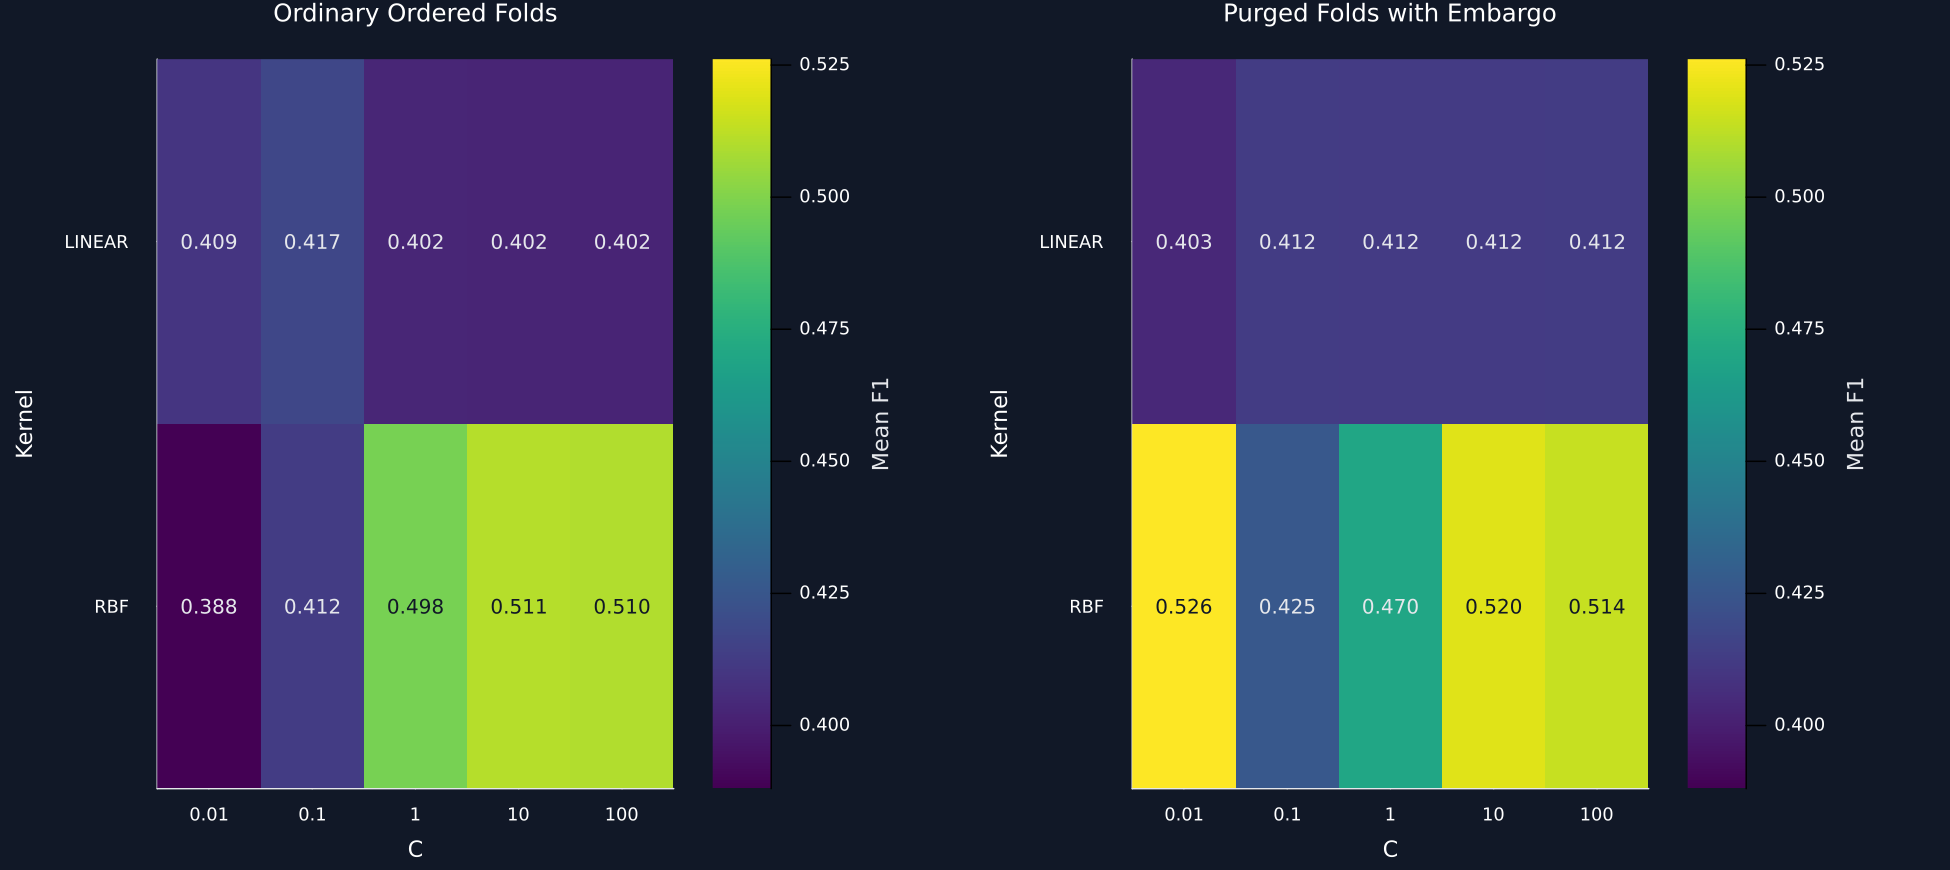

In [3]:
expanded_configurations = configurations([.01,.1,1.,10.,100.])
purged_score_surface,protected_splits = configuration_surface(expanded_configurations;key="expanded_purged")
ordinary_score_surface,ordinary_splits = configuration_surface(expanded_configurations;ordinary=true,key="expanded_ordinary")
purged_best,ordinary_best = selected_row(purged_score_surface),selected_row(ordinary_score_surface)
protection_records = NamedTuple[]
for (fold,((ordinary_train,ordinary_test),(protected_train,protected_test))) in enumerate(zip(ordinary_splits,protected_splits))
    push!(protection_records,(fold=fold,test=length(protected_test),ordinary=length(ordinary_train),protected=length(protected_train),removed=length(ordinary_train)-length(protected_train),overlap_ordinary=overlap_count(ordinary_train,ordinary_test),overlap_protected=overlap_count(protected_train,protected_test)))
end
fold_protection_summary = DataFrame(protection_records)
rename!(fold_protection_summary,["Fold","Test observations","Ordinary training observations","Protected training observations","Removed observations","Ordinary overlapping labels","Protected overlapping labels"])
search_comparison = DataFrame("Validation rule"=>["Ordinary ordered folds","Purged folds with embargo"],"Selected kernel"=>[ordinary_best.Kernel,purged_best.Kernel],"Selected C"=>[ordinary_best.C,purged_best.C],"Selected mean F1"=>[ordinary_best["Mean F1"],purged_best["Mean F1"]],"Selected F1 spread"=>[ordinary_best["F1 spread"],purged_best["F1 spread"]],"Overlapping training labels"=>[sum(fold_protection_summary[!,"Ordinary overlapping labels"]),sum(fold_protection_summary[!,"Protected overlapping labels"])])
table(purged_score_surface,"purged_score_surface","Protected score surface over two kernels and five penalty values.")
table(ordinary_score_surface,"ordinary_score_surface","Ordinary ordered-fold score surface over the same candidate settings.")
table(fold_protection_summary,"fold_protection_summary","Training observations and overlapping labels under ordinary and protected folds.")
table(search_comparison,"search_comparison","Selected settings under ordinary and protected validation.")
limits = extrema(vcat(ordinary_score_surface[!,"Mean F1"],purged_score_surface[!,"Mean F1"]))
panels = []
for (frame,title_text) in [(ordinary_score_surface,"Ordinary Ordered Folds"),(purged_score_surface,"Purged Folds with Embargo")]
    values = permutedims(reshape(frame[!,"Mean F1"],5,2))
    panel = heatmap(1:5,1:2,values;color=:viridis,clims=limits,colorbar_title="Mean F1",yflip=true,xticks=(1:5,["0.01","0.1","1","10","100"]),yticks=(1:2,["LINEAR","RBF"]),xlabel="C",ylabel="Kernel",title=title_text,grid=false)
    for row in 1:2, column in 1:5
        color = values[row,column]>(limits[1]+.62*(limits[2]-limits[1])) ? palette.background : palette.text
        annotate!(panel,column,row,text(@sprintf("%.3f",values[row,column]),9,color,:center))
    end
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(1,2),size=(1300,580),left_margin=7Plots.mm,right_margin=12Plots.mm),paths,"ordinary_purged_score_surfaces")


The cumulative best score after evaluating the first $b$ settings is:

$$
B_b=\max_{1\leq r\leq b}\overline s(\theta_r).
$$

Here, $b$ is the number of evaluated settings, $r$ is their evaluation order, $\theta_r$ is the setting evaluated at step $r$, $\overline s(\theta_r)$ is its protected mean score, and $B_b$ is the best score found within that budget.

## Comparing three search strategies

Row,Released calculation,Selected kernel,Selected C,Candidate evaluations,Fitted members after selection
,String,String,Float64,Int64,Int64
1,Exhaustive protected search,rbf,10.0,4,1
2,Three protected random draws,rbf,10.0,3,1
3,Bagged selected fit,rbf,10.0,1,5


Row,Evaluated settings,Grid-order best F1,Fixed-random-order best F1
,Int64,Float64,Float64
1,1,0.403342,0.519843
2,2,0.412221,0.519843
3,3,0.412221,0.526116
4,4,0.412221,0.526116
5,5,0.412221,0.526116
6,6,0.526116,0.526116
7,7,0.526116,0.526116
8,8,0.526116,0.526116
9,9,0.526116,0.526116


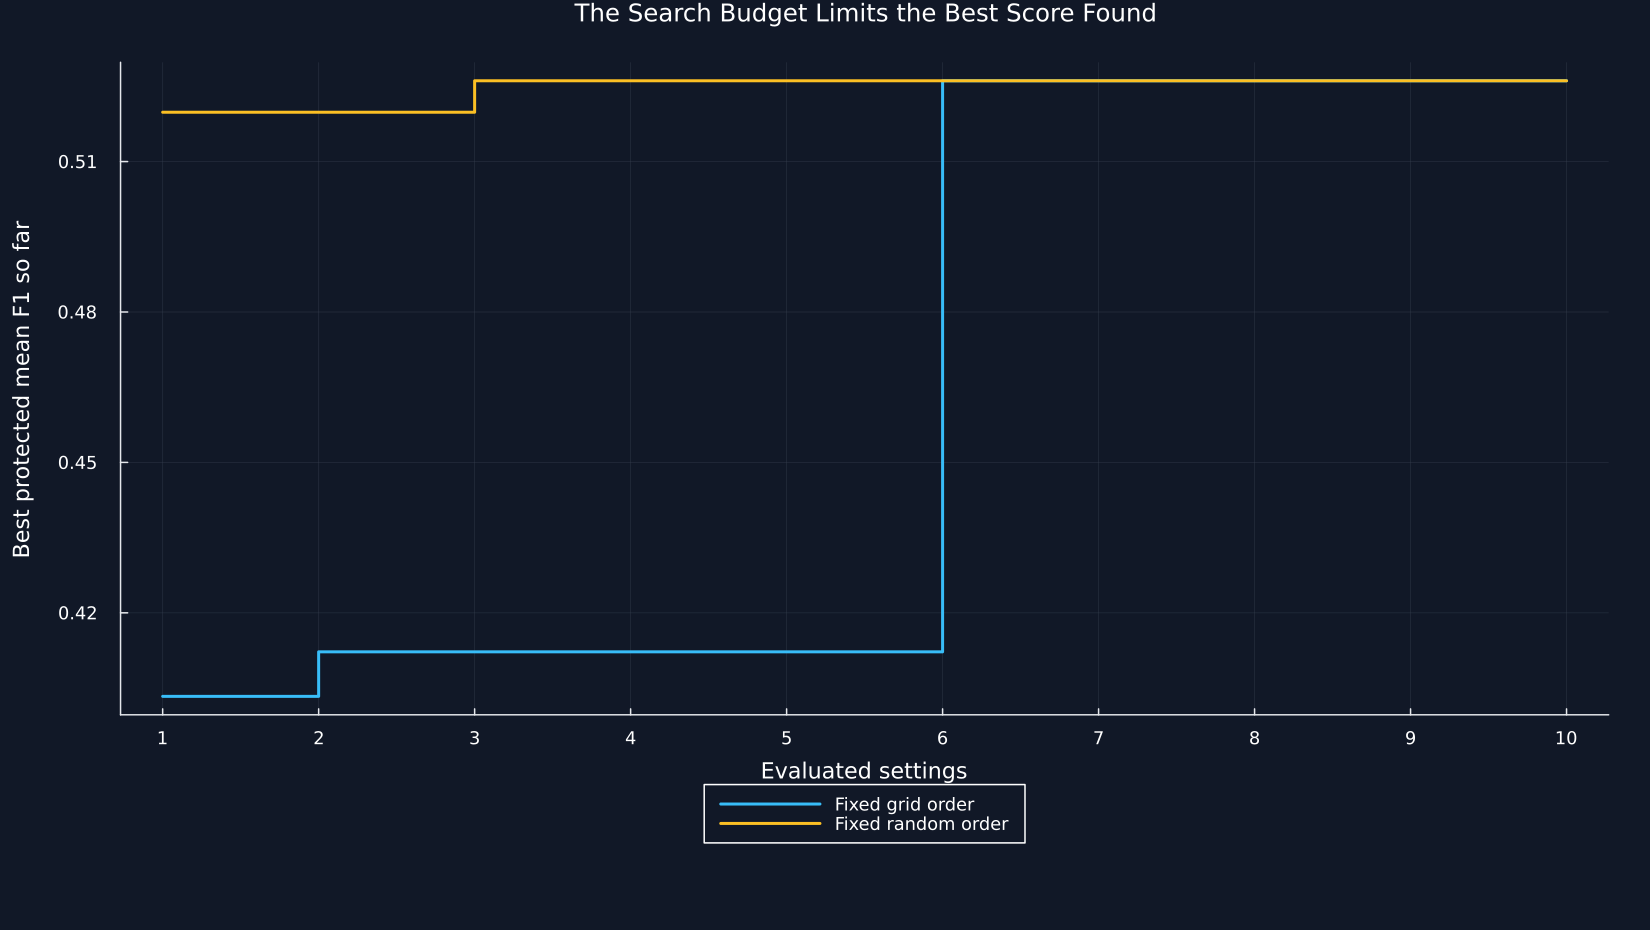

In [4]:
random_candidate_indices = read_primitive("random_candidate_indices.csv").position
random_result = released_search(preliminary_grid,"released_random";weights=sample_weight,random_candidates=random_candidate_indices)
bagged_grid = Dict("svc__kernel"=>[preliminary_best.Kernel],"svc__C"=>[preliminary_best.C])
bagged_result = released_search(bagged_grid,"released_bagged";bagging=[5,.8,1.])
released_search_outputs = DataFrame("Released calculation"=>["Exhaustive protected search","Three protected random draws","Bagged selected fit"],"Selected kernel"=>[result.best_params["svc__kernel"] for result in [preliminary_result,random_result,bagged_result]],"Selected C"=>[result.best_params["svc__C"] for result in [preliminary_result,random_result,bagged_result]],"Candidate evaluations"=>[4,3,1],"Fitted members after selection"=>[1,1,5])
table(released_search_outputs,"released_search_outputs","Outputs from the released exhaustive, random-draw, and bagged search paths.")
ordered_scores = sort(purged_score_surface,:Order)[!,"Mean F1"]
random_order = read_primitive("budget_order.csv").position
@assert sort(random_order)==collect(1:10)
search_budget_path = DataFrame("Evaluated settings"=>collect(1:10),"Grid-order best F1"=>accumulate(max,ordered_scores),"Fixed-random-order best F1"=>accumulate(max,ordered_scores[random_order]))
table(search_budget_path,"search_budget_path","Best protected score reached as the search budget increases.")
figure = plot(1:10,search_budget_path[!,"Grid-order best F1"];seriestype=:steppost,color=palette.cyan,label="Fixed grid order",xlabel="Evaluated settings",ylabel="Best protected mean F1 so far",title="The Search Budget Limits the Best Score Found",xticks=1:10,size=(1100,620),legend=:outerbottom)
plot!(figure,1:10,search_budget_path[!,"Fixed-random-order best F1"];seriestype=:steppost,color=palette.amber,label="Fixed random order")
save_figure(figure,paths,"search_budget_path")


## Tests

In [5]:
@assert size(preliminary_surface)==(4,10)
@assert size(preliminary_reproduction)==(11,2)
@assert preliminary_parameters["svc__kernel"] in ["linear","rbf"]
@assert preliminary_parameters["svc__C"] in [1.,10.]
@assert preliminary_best.Kernel==preliminary_parameters["svc__kernel"]
@assert preliminary_best.C==preliminary_parameters["svc__C"]
@assert size(purged_score_surface)==(10,10)
@assert size(ordinary_score_surface)==(10,8)
@assert all(value->0<=value<=1,purged_score_surface[!,"Mean F1"])
@assert all(value->0<=value<=1,ordinary_score_surface[!,"Mean F1"])
@assert size(fold_protection_summary)==(5,7)
@assert all(>(0),fold_protection_summary[!,"Removed observations"])
@assert all(>(0),fold_protection_summary[!,"Ordinary overlapping labels"])
@assert all(iszero,fold_protection_summary[!,"Protected overlapping labels"])
@assert size(search_comparison)==(2,6)
@assert random_result.best_params["svc__kernel"] in ["linear","rbf"]
@assert random_result.best_params["svc__C"] in [1.,10.]
@assert length(last(only(bagged_result.estimator.steps)).members)==5
@assert bagged_result.best_params["svc__kernel"]==preliminary_best.Kernel
@assert bagged_result.best_params["svc__C"]==preliminary_best.C
@assert size(released_search_outputs)==(3,5)
@assert size(search_budget_path)==(10,3)
@assert issorted(search_budget_path[!,"Grid-order best F1"])
@assert issorted(search_budget_path[!,"Fixed-random-order best F1"])
@assert last(search_budget_path[!,"Grid-order best F1"])≈maximum(purged_score_surface[!,"Mean F1"])
@assert last(search_budget_path[!,"Fixed-random-order best F1"])≈maximum(purged_score_surface[!,"Mean F1"])
@assert all(row.converged for row in fit_records)
@assert isfile(joinpath(paths.figures,"ordinary_purged_score_surfaces.pdf"))
@assert isfile(joinpath(paths.figures,"search_budget_path.pdf"))
@assert isfile(joinpath(paths.tables,"preliminary_search_surface.tex"))
@assert isfile(joinpath(paths.tables,"preliminary_reproduction.tex"))
@assert isfile(joinpath(paths.tables,"purged_score_surface.tex"))
@assert isfile(joinpath(paths.tables,"ordinary_score_surface.tex"))
@assert isfile(joinpath(paths.tables,"fold_protection_summary.tex"))
@assert isfile(joinpath(paths.tables,"search_comparison.tex"))
@assert isfile(joinpath(paths.tables,"released_search_outputs.tex"))
@assert isfile(joinpath(paths.tables,"search_budget_path.tex"))
